# Cristiano Ronaldo — UEFA Champions League Career Analysis

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (candidate for candidate in project_candidates if (candidate / "data" / "matches").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing data/matches.")

MATCH_DIR = PROJECT_ROOT / "data" / "matches"
CHART_DIR = PROJECT_ROOT / "public" / "images" / "articles"
UCL_LABEL = "UEFA Champions League"
CHART_DIR.mkdir(parents=True, exist_ok=True)
print(f"Loading matches from: {MATCH_DIR.resolve()}")
print(f"Saving charts to: {CHART_DIR.resolve()}")

records = []
for p in sorted(MATCH_DIR.glob("*.json")):
    with p.open(encoding="utf-8") as f:
        obj = json.load(f)
    items = obj if isinstance(obj, list) else obj.get("matches", []) if isinstance(obj, dict) else []
    records.extend({**r, "_source_file": p.name} for r in items if isinstance(r, dict))
if not records:
    raise ValueError(f"No match records found in {MATCH_DIR}")
all_matches = pd.json_normalize(records, sep=".")
print("Competition labels:")
display(all_matches["competition"].value_counts(dropna=False).to_frame("matches"))


ucl = all_matches[all_matches["competition"].astype(str).str.strip().eq(UCL_LABEL)].copy()
if ucl.empty:
    raise ValueError(f"No rows matched {UCL_LABEL!r}; check the labels printed above.")
for c in ["goals", "assists", "scoreFor", "scoreAgainst", "minutesPlayed",
          "stats.shots", "stats.keyPasses", "stats.bigChancesCreated",
          "stats.successfulDribbles", "stats.accurateThroughballs"]:
    if c not in ucl:
        ucl[c] = np.nan
    ucl[c] = pd.to_numeric(ucl[c], errors="coerce")
for c in ["stage", "opponent", "venue", "result", "season", "date"]:
    if c not in ucl:
        ucl[c] = np.nan
ucl["date"] = pd.to_datetime(ucl["date"], errors="coerce")
ucl["goals"] = ucl["goals"].fillna(0)
ucl["assists"] = ucl["assists"].fillna(0)
ucl["stage"] = ucl["stage"].fillna("Unknown").astype(str)
ucl["opponent"] = ucl["opponent"].fillna("Unknown").astype(str)
ucl["venue"] = ucl["venue"].fillna("Unknown").astype(str)
ucl["result"] = ucl["result"].fillna("Unknown").astype(str).str.upper()
ucl["season"] = ucl["season"].fillna("Unknown").astype(str)
ucl["match_label"] = (
    ucl["date"].dt.strftime("%Y-%m-%d").fillna("Unknown date")
    + " - " + ucl["opponent"] + " - " + ucl["stage"]
)
print(f"UCL records: {len(ucl)}")
print("Stage labels:")
display(ucl["stage"].value_counts().to_frame("matches"))
print("Venue labels:")
display(ucl["venue"].value_counts(dropna=False).to_frame("matches"))

def savefig(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()


Loading matches from: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive\data\matches
Saving charts to: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive\public\images\articles
Competition labels:


,matches
competition,
La Liga,292
Premier League,236
UEFA Champions League,183
Saudi Pro League,116
Serie A,98
International Friendly,56
FIFA World Cup Qualifier,52
UEFA European Championship Qualifying,44
Copa del Rey,30


UCL records: 183
Stage labels:


,matches
stage,
Group Stage,98
Round of 16,36
Quarter-final,22
Semi-final,21
Final,6


Venue labels:


,matches
venue,
Away,91
Home,86
Neutral,6


1. Goals by round

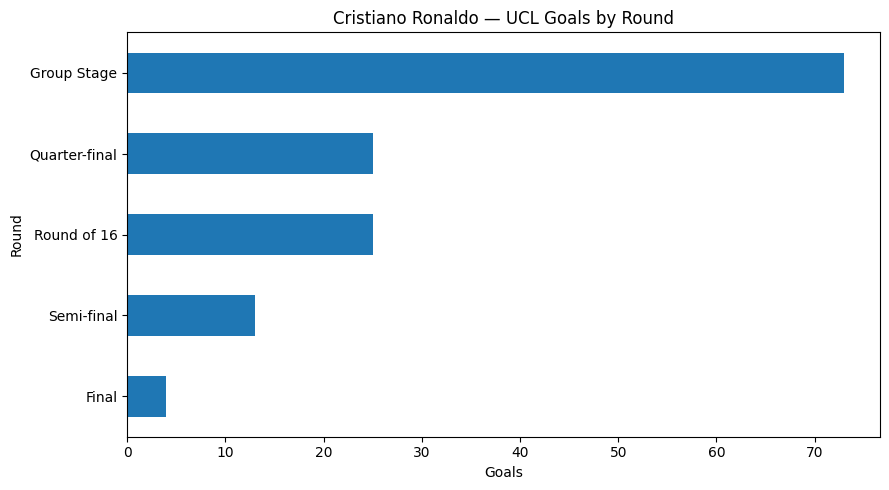

,goals
stage,
Group Stage,73
Quarter-final,25
Round of 16,25
Semi-final,13
Final,4


In [18]:
v = ucl.groupby("stage")["goals"].sum().sort_values()
v.plot(kind="barh", figsize=(9, 5), title="Cristiano Ronaldo — UCL Goals by Round")
plt.xlabel("Goals"); plt.ylabel("Round")
savefig("ronaldo-ucl-goals-by-round.png")
display(v.sort_values(ascending=False).rename("goals").to_frame())

2. Favorite opponents by goals — top 10

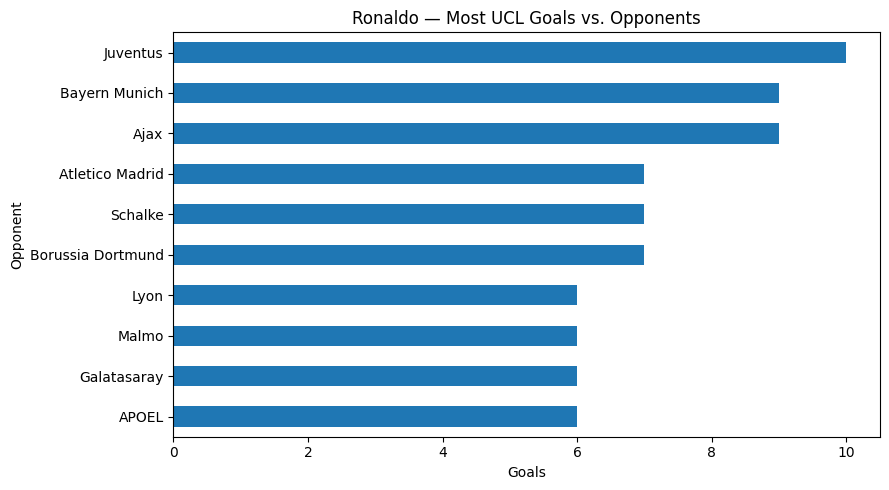

,goals
opponent,
Juventus,10
Ajax,9
Bayern Munich,9
Atletico Madrid,7
Borussia Dortmund,7
Schalke,7
Galatasaray,6
APOEL,6
Malmo,6


In [19]:
v = ucl.groupby("opponent")["goals"].sum().nlargest(10).sort_values()
v.plot(kind="barh", figsize=(9, 5), title="Ronaldo — Most UCL Goals vs. Opponents")
plt.xlabel("Goals"); plt.ylabel("Opponent")
savefig("ronaldo-ucl-goals-by-opponent.png")
display(v.sort_values(ascending=False).rename("goals").to_frame())

3. Results against most-faced opponents

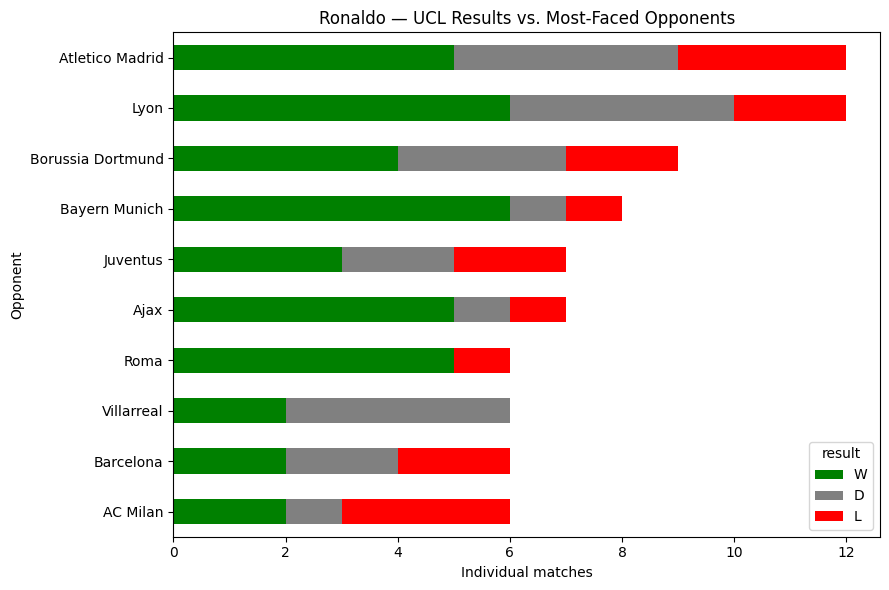

result,W,D,L
opponent,,,
AC Milan,2,1,3
Barcelona,2,2,2
Villarreal,2,4,0
Roma,5,0,1
Ajax,5,1,1
Juventus,3,2,2
Bayern Munich,6,1,1
Borussia Dortmund,4,3,2
Lyon,6,4,2


In [20]:
top = ucl["opponent"].value_counts().head(10).index
v = (ucl[ucl.opponent.isin(top)].groupby(["opponent", "result"]).size()
     .unstack(fill_value=0).reindex(columns=["W", "D", "L"], fill_value=0))
v = v.loc[v.sum(axis=1).sort_values().index]
v.plot(kind="barh", stacked=True, figsize=(9, 6),
       color={"W":"green", "D":"gray", "L":"red"},
       title="Ronaldo — UCL Results vs. Most-Faced Opponents")
plt.xlabel("Individual matches"); plt.ylabel("Opponent")
savefig("ronaldo-ucl-results-by-opponent.png")
display(v)

4. Man of the Match by round

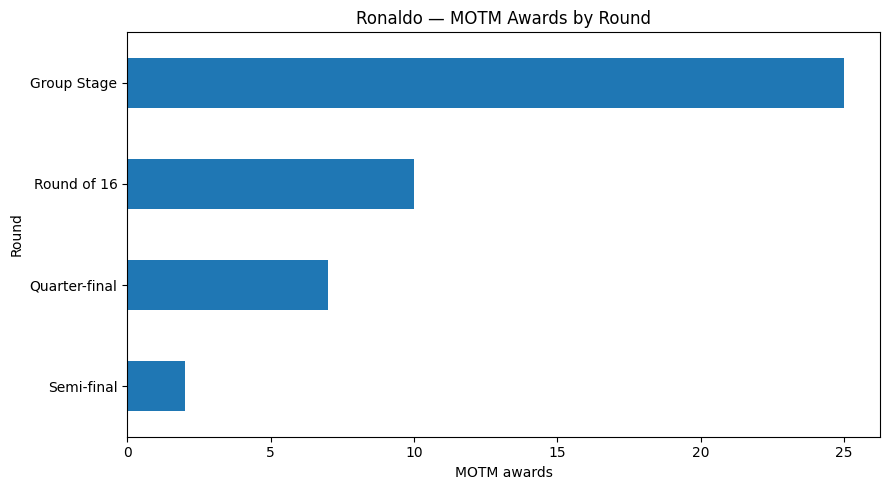

Matches with a recorded MOTM value: 183


,MOTM awards
stage,
Group Stage,25
Round of 16,10
Quarter-final,7
Semi-final,2


In [21]:
def bool_value(x):
    if isinstance(x, (bool, np.bool_)): return bool(x)
    if isinstance(x, (int, float)) and not pd.isna(x) and x in (0, 1): return bool(x)
    if isinstance(x, str) and x.strip().lower() in {"true","yes","1"}: return True
    if isinstance(x, str) and x.strip().lower() in {"false","no","0"}: return False
    return np.nan
motm = ucl["stats.motm"].map(bool_value) if "stats.motm" in ucl else pd.Series(np.nan, index=ucl.index)
v = ucl.loc[motm.eq(True)].groupby("stage").size().sort_values()
v.plot(kind="barh", figsize=(9, 5), title="Ronaldo — MOTM Awards by Round")
plt.xlabel("MOTM awards"); plt.ylabel("Round")
savefig("ronaldo-ucl-motm-by-round.png")
print("Matches with a recorded MOTM value:", int(motm.notna().sum()))
display(v.sort_values(ascending=False).rename("MOTM awards").to_frame())

5. Top five successful-dribbling matches

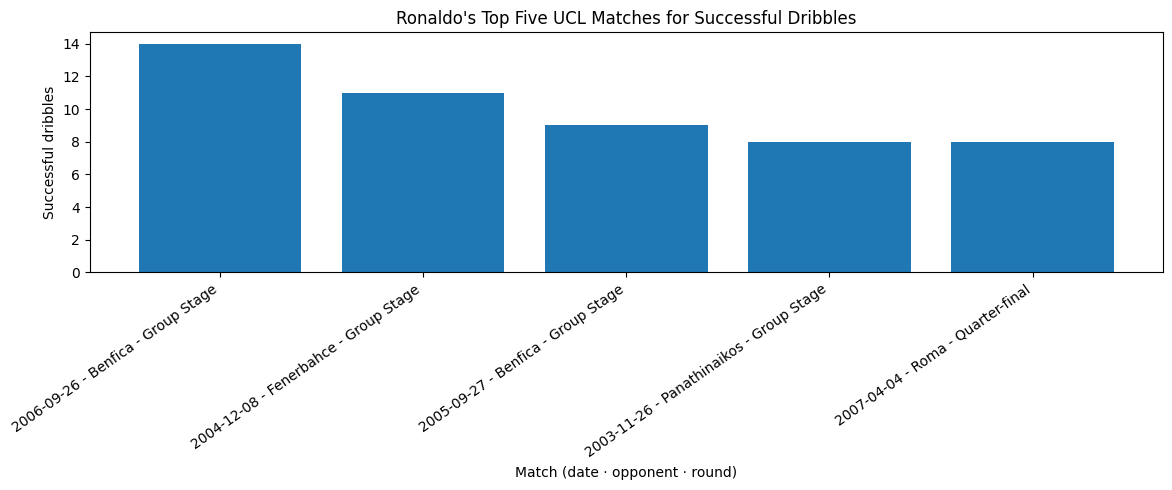

,date,opponent,stage,stats.successfulDribbles,match_label
0,2006-09-26,Benfica,Group Stage,14.0,2006-09-26 - Benfica - Group Stage
1,2004-12-08,Fenerbahce,Group Stage,11.0,2004-12-08 - Fenerbahce - Group Stage
2,2005-09-27,Benfica,Group Stage,9.0,2005-09-27 - Benfica - Group Stage
3,2003-11-26,Panathinaikos,Group Stage,8.0,2003-11-26 - Panathinaikos - Group Stage
4,2007-04-04,Roma,Quarter-final,8.0,2007-04-04 - Roma - Quarter-final


In [22]:
col = "stats.successfulDribbles"
v = ucl[ucl[col].notna()].sort_values([col, "date"], ascending=[False, True]).head(5)
if v.empty: print("No recorded successful-dribble match stats.")
else:
    plt.figure(figsize=(12, 5))
    plt.bar(v.match_label, v[col])
    plt.title("Ronaldo's Top Five UCL Matches for Successful Dribbles")
    plt.xlabel("Match (date · opponent · round)"); plt.ylabel("Successful dribbles")
    plt.xticks(rotation=35, ha="right")
    savefig("ronaldo-ucl-top-dribbling-performances.png")
    display(v[["date","opponent","stage",col,"match_label"]].reset_index(drop=True))

6. Top five key-pass matches

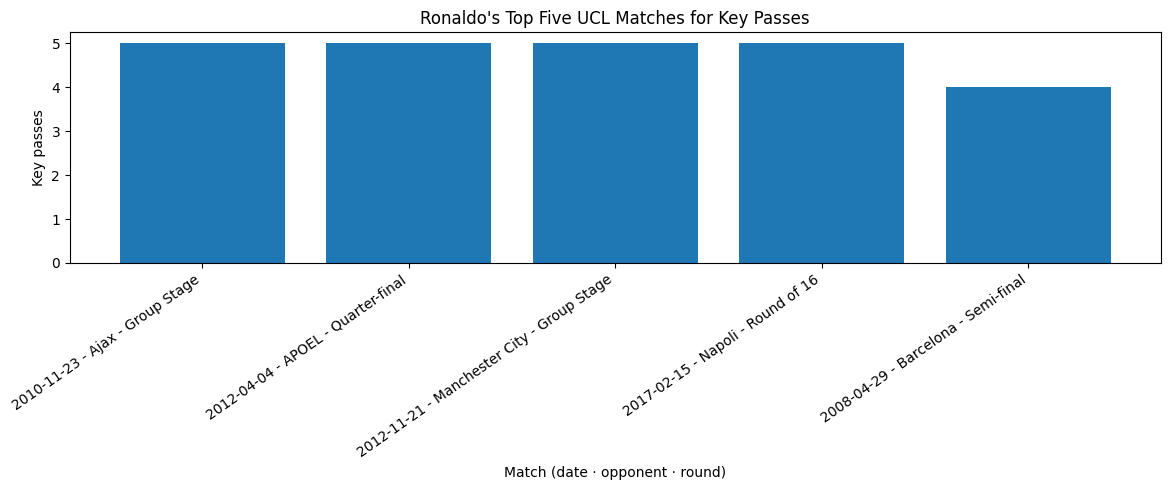

,date,opponent,stage,stats.keyPasses,match_label
0,2010-11-23,Ajax,Group Stage,5.0,2010-11-23 - Ajax - Group Stage
1,2012-04-04,APOEL,Quarter-final,5.0,2012-04-04 - APOEL - Quarter-final
2,2012-11-21,Manchester City,Group Stage,5.0,2012-11-21 - Manchester City - Group Stage
3,2017-02-15,Napoli,Round of 16,5.0,2017-02-15 - Napoli - Round of 16
4,2008-04-29,Barcelona,Semi-final,4.0,2008-04-29 - Barcelona - Semi-final


In [23]:
col = "stats.keyPasses"
v = ucl[ucl[col].notna()].sort_values([col, "date"], ascending=[False, True]).head(5)
if v.empty: print("No recorded key-pass match stats.")
else:
    plt.figure(figsize=(12, 5))
    plt.bar(v.match_label, v[col])
    plt.title("Ronaldo's Top Five UCL Matches for Key Passes")
    plt.xlabel("Match (date · opponent · round)"); plt.ylabel("Key passes")
    plt.xticks(rotation=35, ha="right")
    savefig("ronaldo-ucl-top-key-pass-performances.png")
    display(v[["date","opponent","stage",col,"match_label"]].reset_index(drop=True))
# This chart uses key passes only; throughballs and big chances created are not combined here.

7. Distribution of matches with 1, 2, 3, or 4 goals

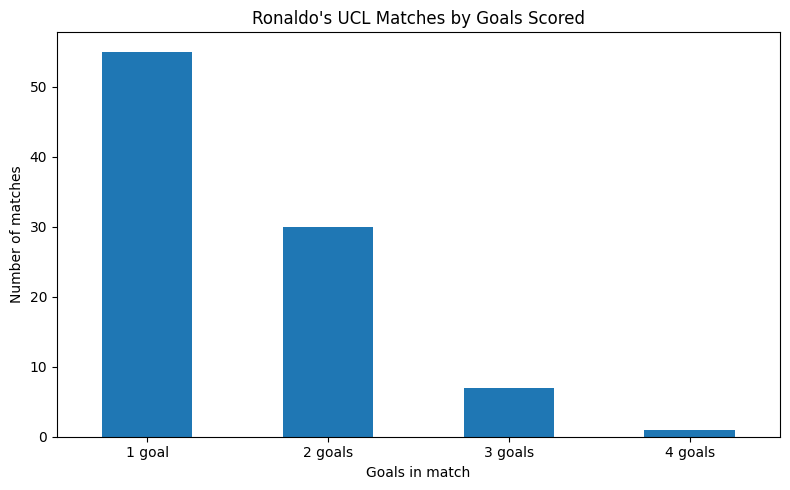

,matches
1 goal,55
2 goals,30
3 goals,7
4 goals,1


Zero-goal matches are intentionally omitted from this chart.


In [24]:
counts = pd.Series({f"{n} goal{'s' if n != 1 else ''}": int((ucl.goals == n).sum())
                     for n in [1,2,3,4]}, name="matches")
counts.plot(kind="bar", figsize=(8, 5), title="Ronaldo's UCL Matches by Goals Scored")
plt.xlabel("Goals in match"); plt.ylabel("Number of matches")
plt.xticks(rotation=0)
savefig("ronaldo-ucl-goal-distribution.png")
display(counts.to_frame())
print("Zero-goal matches are intentionally omitted from this chart.")

8. Home vs. away goals by round

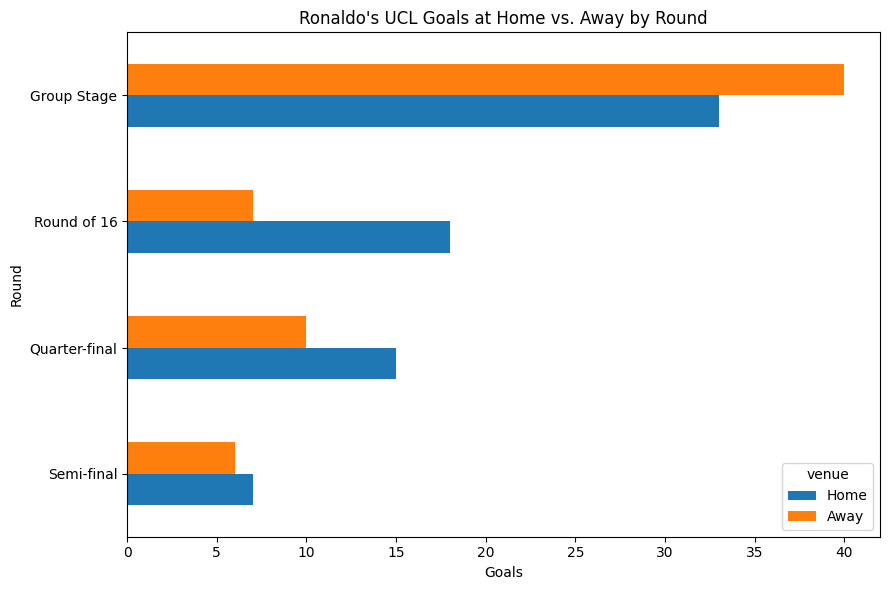

venue,Home,Away
stage,,
Semi-final,7,6
Quarter-final,15,10
Round of 16,18,7
Group Stage,33,40


In [25]:
venue = ucl.venue.str.strip().str.lower()
d = ucl[venue.isin(["home","away"])].copy()
d["venue"] = venue[venue.isin(["home","away"])].map({"home":"Home","away":"Away"})
v = d.groupby(["stage","venue"])["goals"].sum().unstack(fill_value=0).reindex(columns=["Home","Away"], fill_value=0)
v = v.loc[v.sum(axis=1).sort_values().index]
v.plot(kind="barh", figsize=(9, 6), title="Ronaldo's UCL Goals at Home vs. Away by Round")
plt.xlabel("Goals"); plt.ylabel("Round")
savefig("ronaldo-ucl-home-away-goals-by-round.png")
display(v)

9. Outlier scoring performances

Highest goal totals in one UCL match:


,date,team,opponent,stage,goals,stats.shots,match_label
0,2015-12-08,Real Madrid,Malmo,Group Stage,4,10.0,2015-12-08 - Malmo - Group Stage
1,2012-10-03,Real Madrid,Ajax,Group Stage,3,9.0,2012-10-03 - Ajax - Group Stage
2,2013-09-17,Real Madrid,Galatasaray,Group Stage,3,9.0,2013-09-17 - Galatasaray - Group Stage
3,2015-09-15,Real Madrid,Shakhtar Donetsk,Group Stage,3,10.0,2015-09-15 - Shakhtar Donetsk - Group Stage
4,2016-04-12,Real Madrid,Wolfsburg,Quarter-final,3,5.0,2016-04-12 - Wolfsburg - Quarter-final
5,2017-04-18,Real Madrid,Bayern Munich,Quarter-final,3,9.0,2017-04-18 - Bayern Munich - Quarter-final
6,2017-05-02,Real Madrid,Atletico Madrid,Semi-final,3,5.0,2017-05-02 - Atletico Madrid - Semi-final
7,2019-03-12,Juventus,Atletico Madrid,Round of 16,3,5.0,2019-03-12 - Atletico Madrid - Round of 16
8,2007-04-10,Manchester United,Roma,Quarter-final,2,10.0,2007-04-10 - Roma - Quarter-final
9,2007-10-23,Manchester United,Dynamo Kyiv,Group Stage,2,5.0,2007-10-23 - Dynamo Kyiv - Group Stage


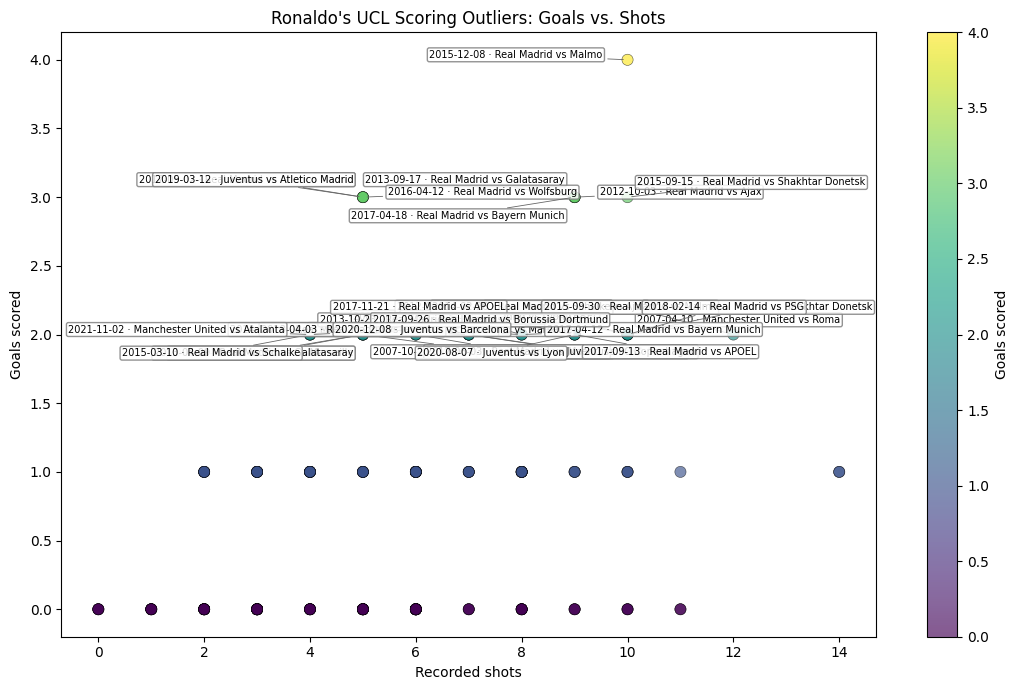

Best shot-conversion rates among scoring matches (minimum 3 recorded shots):


,date,team,opponent,stage,goals,stats.shots,shot_conversion_rate,match_label
0,2016-04-12,Real Madrid,Wolfsburg,Quarter-final,3,5.0,0.6,2016-04-12 - Wolfsburg - Quarter-final
1,2017-05-02,Real Madrid,Atletico Madrid,Semi-final,3,5.0,0.6,2017-05-02 - Atletico Madrid - Semi-final
2,2019-03-12,Juventus,Atletico Madrid,Round of 16,3,5.0,0.6,2019-03-12 - Atletico Madrid - Round of 16
3,2013-10-23,Real Madrid,Juventus,Group Stage,2,4.0,0.5,2013-10-23 - Juventus - Group Stage
4,2015-03-10,Real Madrid,Schalke,Round of 16,2,4.0,0.5,2015-03-10 - Schalke - Round of 16
5,2020-12-08,Juventus,Barcelona,Group Stage,2,4.0,0.5,2020-12-08 - Barcelona - Group Stage
6,2021-11-02,Manchester United,Atalanta,Group Stage,2,4.0,0.5,2021-11-02 - Atalanta - Group Stage
7,2015-12-08,Real Madrid,Malmo,Group Stage,4,10.0,0.4,2015-12-08 - Malmo - Group Stage
8,2007-10-23,Manchester United,Dynamo Kyiv,Group Stage,2,5.0,0.4,2007-10-23 - Dynamo Kyiv - Group Stage
9,2009-12-08,Real Madrid,Marseille,Group Stage,2,5.0,0.4,2009-12-08 - Marseille - Group Stage


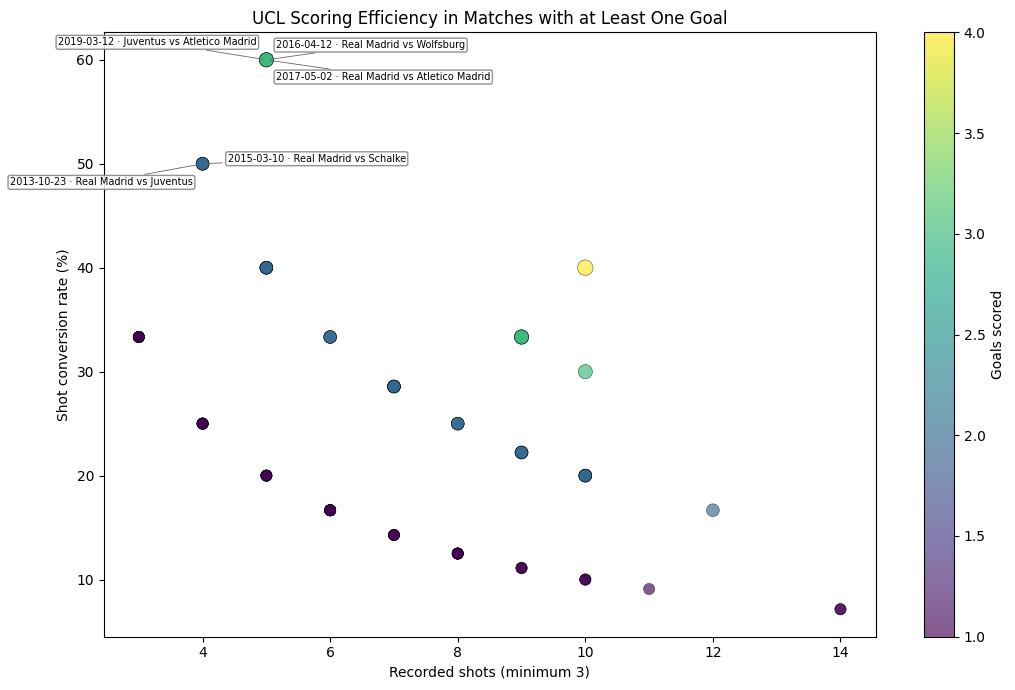

Interpret conversion rates cautiously: they depend on complete, consistent shot data.


In [31]:
# Match labels include the date, Ronaldo's team, opponent, and round.
# adjustText spreads labels apart and draws leader lines. If it is not installed,
# the notebook still runs with staggered labels; install with: pip install adjustText
try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None


def annotate_match_labels(ax, frame, x_col, y_col, label_frame, fontsize=7):
    texts = []
    for _, row in label_frame.iterrows():
        date = row["date"].strftime("%Y-%m-%d") if pd.notna(row["date"]) else "Unknown date"
        team = str(row.get("team", "Unknown team"))
        opponent = str(row.get("opponent", "Unknown opponent"))
        label = f"{date} · {team} vs {opponent}"
        texts.append(ax.annotate(
            label,
            (row[x_col], row[y_col]),
            xytext=(7, 7), textcoords="offset points", fontsize=fontsize,
            ha="left", va="bottom",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.5", alpha=0.85),
            arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=3),
        ))
    if texts and adjust_text is not None:
        adjust_text(
            texts, x=frame[x_col].to_numpy(), y=frame[y_col].to_numpy(), ax=ax,
            expand=(1.15, 1.25), force_text=(0.6, 0.8), force_static=(0.4, 0.6),
            arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6),
        )
    elif texts:
        # Fallback: distribute labels around their points in a repeating pattern.
        offsets = [(7, 7), (7, -16), (-7, 9), (-7, -17), (18, 0), (-18, 0), (12, 16), (-12, 16)]
        for i, ann in enumerate(texts):
            ann.set_position(offsets[i % len(offsets)])
            ann.set_ha("left" if offsets[i % len(offsets)][0] >= 0 else "right")

print("Highest goal totals in one UCL match:")
display(ucl[ucl.goals > 0].sort_values(["goals","date"], ascending=[False,True])
        [["date","team","opponent","stage","goals","stats.shots","match_label"]].head(10).reset_index(drop=True))

# Scatterplot: goals scored against shots taken. Matches above the general pattern
# are potential scoring outliers; shot data may be incomplete for older matches.
d = ucl[ucl["stats.shots"].notna() & (ucl["stats.shots"] >= 0)].copy()
if d.empty:
    print("No recorded shot data available for the scoring scatterplot.")
else:
    fig, ax = plt.subplots(figsize=(11, 7))
    points = ax.scatter(d["stats.shots"], d["goals"], c=d["goals"], s=65,
                        alpha=0.65, edgecolors="black", linewidths=0.4)
    fig.colorbar(points, ax=ax, label="Goals scored")
    ax.set_title("Ronaldo's UCL Scoring Outliers: Goals vs. Shots")
    ax.set_xlabel("Recorded shots")
    ax.set_ylabel("Goals scored")
    # Label multi-goal matches, including full match details. Labels are repelled
    # where possible to avoid appearing to belong to another point.
    label_rows = d[d["goals"] >= 2].copy()
    annotate_match_labels(ax, d, "stats.shots", "goals", label_rows, fontsize=7)
    savefig("ronaldo-ucl-scoring-outliers.png")

# Conversion rate is only calculated when at least three shots are recorded.
d = ucl[ucl["stats.shots"].notna() & (ucl["stats.shots"] >= 3) & (ucl.goals > 0)].copy()
d["shot_conversion_rate"] = d.goals / d["stats.shots"]
print("Best shot-conversion rates among scoring matches (minimum 3 recorded shots):")
display(d.sort_values(["shot_conversion_rate","goals"], ascending=False)
        [["date","team","opponent","stage","goals","stats.shots","shot_conversion_rate","match_label"]]
        .head(10).reset_index(drop=True))
if not d.empty:
    fig, ax = plt.subplots(figsize=(11, 7))
    points = ax.scatter(d["stats.shots"], d["shot_conversion_rate"] * 100,
                        c=d["goals"], s=45 + d["goals"] * 20,
                        alpha=0.65, edgecolors="black", linewidths=0.4)
    fig.colorbar(points, ax=ax, label="Goals scored")
    ax.set_title("UCL Scoring Efficiency in Matches with at Least One Goal")
    ax.set_xlabel("Recorded shots (minimum 3)")
    ax.set_ylabel("Shot conversion rate (%)")
    plot_d = d.assign(shot_conversion_rate=d["shot_conversion_rate"] * 100)
    label_rows = plot_d.sort_values(["shot_conversion_rate", "goals"], ascending=False).head(5)
    annotate_match_labels(ax, plot_d, "stats.shots", "shot_conversion_rate", label_rows, fontsize=7)
    savefig("ronaldo-ucl-shot-conversion-outliers.png")
print("Interpret conversion rates cautiously: they depend on complete, consistent shot data.")

10. Outlier assisting and creative performances

Top matches by assists


,date,team,opponent,stage,assists,assists,match_label
0,2015-11-25,Real Madrid,Shakhtar Donetsk,Group Stage,2,2,2015-11-25 - Shakhtar Donetsk - Group Stage
1,2016-10-18,Real Madrid,Legia Warsaw,Group Stage,2,2,2016-10-18 - Legia Warsaw - Group Stage
2,2004-09-15,Manchester United,Lyon,Group Stage,1,1,2004-09-15 - Lyon - Group Stage
3,2006-09-26,Manchester United,Benfica,Group Stage,1,1,2006-09-26 - Benfica - Group Stage
4,2006-10-17,Manchester United,FC Copenhagen,Group Stage,1,1,2006-10-17 - FC Copenhagen - Group Stage
5,2006-12-06,Manchester United,Benfica,Group Stage,1,1,2006-12-06 - Benfica - Group Stage
6,2007-03-07,Manchester United,Lille,Round of 16,1,1,2007-03-07 - Lille - Round of 16
7,2007-04-10,Manchester United,Roma,Quarter-final,1,1,2007-04-10 - Roma - Quarter-final
8,2007-11-27,Manchester United,Sporting CP,Group Stage,1,1,2007-11-27 - Sporting CP - Group Stage
9,2008-09-30,Manchester United,Aalborg BK,Group Stage,1,1,2008-09-30 - Aalborg BK - Group Stage


Top matches by key passes


,date,team,opponent,stage,stats.keyPasses,assists,match_label
0,2010-11-23,Real Madrid,Ajax,Group Stage,5.0,0,2010-11-23 - Ajax - Group Stage
1,2012-04-04,Real Madrid,APOEL,Quarter-final,5.0,0,2012-04-04 - APOEL - Quarter-final
2,2012-11-21,Real Madrid,Manchester City,Group Stage,5.0,0,2012-11-21 - Manchester City - Group Stage
3,2017-02-15,Real Madrid,Napoli,Round of 16,5.0,1,2017-02-15 - Napoli - Round of 16
4,2008-04-29,Manchester United,Barcelona,Semi-final,4.0,0,2008-04-29 - Barcelona - Semi-final
5,2008-11-25,Manchester United,Villarreal,Group Stage,4.0,0,2008-11-25 - Villarreal - Group Stage
6,2011-10-18,Real Madrid,Lyon,Group Stage,4.0,1,2011-10-18 - Lyon - Group Stage
7,2013-10-02,Real Madrid,FC Copenhagen,Group Stage,4.0,0,2013-10-02 - FC Copenhagen - Group Stage
8,2014-03-18,Real Madrid,Schalke,Round of 16,4.0,0,2014-03-18 - Schalke - Round of 16
9,2015-11-25,Real Madrid,Shakhtar Donetsk,Group Stage,4.0,2,2015-11-25 - Shakhtar Donetsk - Group Stage


Top matches by big chances created


,date,team,opponent,stage,stats.bigChancesCreated,assists,match_label
0,2011-10-18,Real Madrid,Lyon,Group Stage,3.0,1,2011-10-18 - Lyon - Group Stage
1,2010-10-19,Real Madrid,AC Milan,Group Stage,2.0,1,2010-10-19 - AC Milan - Group Stage
2,2014-03-18,Real Madrid,Schalke,Round of 16,2.0,0,2014-03-18 - Schalke - Round of 16
3,2015-12-08,Real Madrid,Malmo,Group Stage,2.0,1,2015-12-08 - Malmo - Group Stage
4,2016-12-07,Real Madrid,Borussia Dortmund,Group Stage,2.0,0,2016-12-07 - Borussia Dortmund - Group Stage
5,2017-02-15,Real Madrid,Napoli,Round of 16,2.0,1,2017-02-15 - Napoli - Round of 16
6,2018-04-03,Real Madrid,Juventus,Quarter-final,2.0,1,2018-04-03 - Juventus - Quarter-final
7,2018-11-07,Juventus,Manchester United,Group Stage,2.0,0,2018-11-07 - Manchester United - Group Stage
8,2010-11-23,Real Madrid,Ajax,Group Stage,1.0,0,2010-11-23 - Ajax - Group Stage
9,2010-12-08,Real Madrid,Auxerre,Group Stage,1.0,1,2010-12-08 - Auxerre - Group Stage


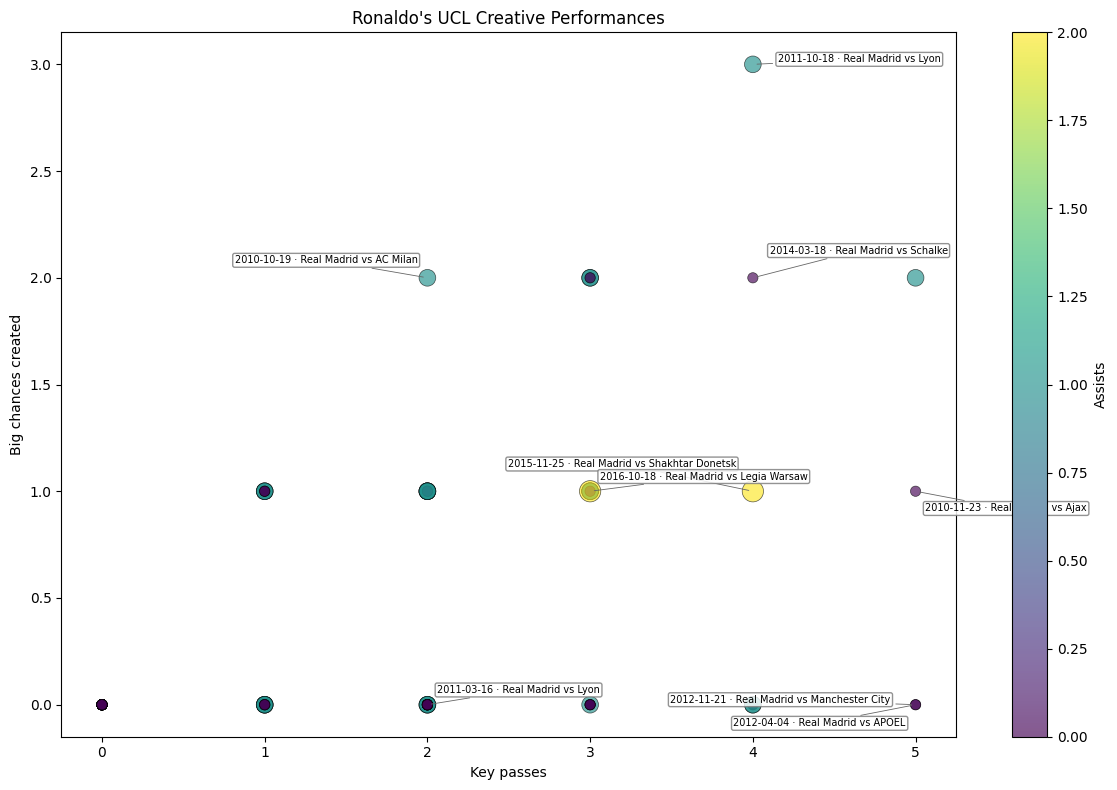

In [32]:
# Rank these separately: assists, key passes, and big chances created.
# Throughballs are intentionally excluded.
for label, col in [("assists","assists"), ("key passes","stats.keyPasses"),
                    ("big chances created","stats.bigChancesCreated")]:
    d = ucl[ucl[col].notna() & (ucl[col] > 0)].sort_values([col,"date"], ascending=[False,True])
    print("Top matches by", label)
    if d.empty: print("No positive recorded values.")
    else: display(d[["date","team","opponent","stage",col,"assists","match_label"]].head(10).reset_index(drop=True))

# Scatterplot: creative actions in the same match. Bubble size and color both
# reflect assists; labels identify matches that stand out in at least one measure.
d = ucl[ucl["stats.keyPasses"].notna() & ucl["stats.bigChancesCreated"].notna()].copy()
if d.empty:
    print("No matches have both recorded key-pass and big-chance-created values.")
else:
    d["assist_bubble_size"] = 55 + d["assists"].clip(lower=0) * 90
    fig, ax = plt.subplots(figsize=(12, 8))
    points = ax.scatter(d["stats.keyPasses"], d["stats.bigChancesCreated"],
                        s=d["assist_bubble_size"], c=d["assists"],
                        cmap="viridis", alpha=0.65, edgecolors="black", linewidths=0.5)
    fig.colorbar(points, ax=ax, label="Assists")
    ax.set_title("Ronaldo's UCL Creative Performances")
    ax.set_xlabel("Key passes")
    ax.set_ylabel("Big chances created")
    # Label matches among the top performers in any of the three creative measures.
    label_indices = set()
    for col in ["assists", "stats.keyPasses", "stats.bigChancesCreated"]:
        label_indices.update(d.nlargest(3, col).index.tolist())
    label_rows = d.loc[d.index.isin(label_indices)].copy()
    annotate_match_labels(ax, d, "stats.keyPasses", "stats.bigChancesCreated", label_rows, fontsize=7)
    savefig("ronaldo-ucl-creative-performances-scatter.png")


11. Win rate by stage — knockout ties counted once

Group-stage matches are counted individually. Other than finals, knockout records are grouped by season, opponent, and stage; summed scores are used to estimate the tie outcome. This assumes those fields distinguish each tie. Please inspect the tie table below for unexpected groupings.

**Penalty-shootout limitation:** no reliable shootout outcome field is assumed. An aggregate-score tie is classified as D even if the team advanced on penalties, so mention this caveat when describing the result.

result,W,D,L,units,win_rate_pct
stage,,,,,
Quarter-final,11,0,1,12,91.666667
Group Stage,68,19,11,98,69.387755
Round of 16,12,2,4,18,66.666667
Semi-final,6,1,4,11,54.545455
Final,3,2,1,6,50.000000


Knockout tie grouping details:


,season,stage,opponent,result,unit,legs,aggregate_for,aggregate_against
0,2003/04,Round of 16,FC Porto,L,knockout tie,2,2,3
1,2004/05,Round of 16,AC Milan,L,knockout tie,2,0,2
2,2006/07,Quarter-final,Roma,W,knockout tie,2,8,3
3,2006/07,Round of 16,Lille,W,knockout tie,2,2,0
4,2006/07,Semi-final,AC Milan,L,knockout tie,2,3,5
5,2007/08,Quarter-final,Roma,W,knockout tie,1,2,0
6,2007/08,Round of 16,Lyon,W,knockout tie,2,2,1
7,2007/08,Semi-final,Barcelona,W,knockout tie,2,1,0
8,2008/09,Quarter-final,FC Porto,W,knockout tie,2,3,2
9,2008/09,Round of 16,Inter Milan,W,knockout tie,2,2,0


Units with unavailable outcome: 0


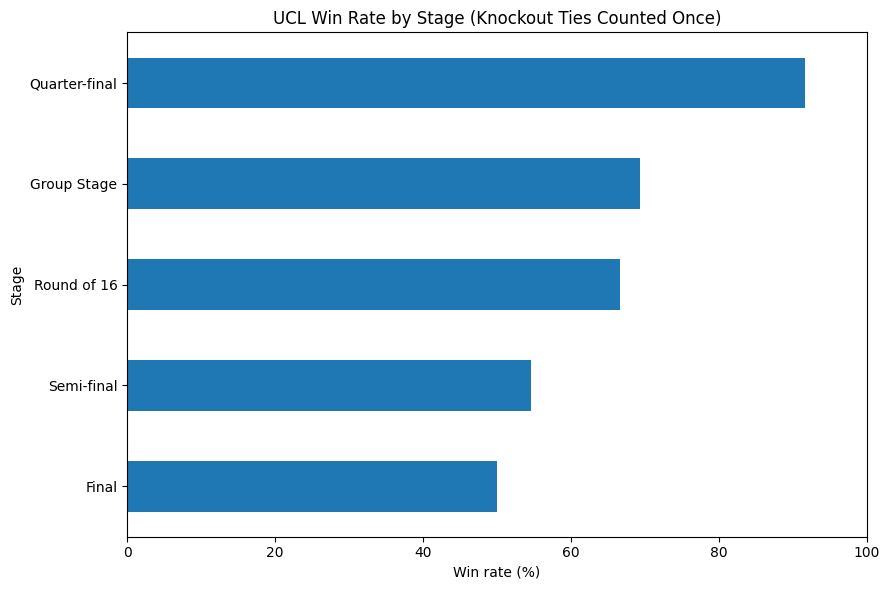

In [28]:
group_mask = ucl.stage.str.strip().str.lower().isin({"group stage","group","league phase"})
groups = ucl[group_mask].copy()
ko = ucl[~group_mask].copy()
final_mask = ko.stage.str.strip().str.lower().eq("final")
finals, ties = ko[final_mask].copy(), ko[~final_mask].copy()

rows = []
# Group-stage matches count individually.
for _, r in groups.iterrows():
    rows.append({"season":r.season,"stage":r.stage,"opponent":r.opponent,
                 "result":r.result,"unit":"group match"})
# Finals are single-match ties.
for _, r in finals.iterrows():
    rows.append({"season":r.season,"stage":r.stage,"opponent":r.opponent,
                 "result":r.result,"unit":"final"})
tie_rows = []
for (season, opponent, stage), g in ties.groupby(["season","opponent","stage"], dropna=False):
    if g[["scoreFor","scoreAgainst"]].isna().any().any():
        outcome = g.iloc[0].result if len(g) == 1 else "Unknown"
        sf, sa = g.scoreFor.sum(min_count=1), g.scoreAgainst.sum(min_count=1)
    else:
        sf, sa = g.scoreFor.sum(), g.scoreAgainst.sum()
        outcome = "W" if sf > sa else "L" if sf < sa else "D"
    row = {"season":season,"stage":stage,"opponent":opponent,"result":outcome,
           "unit":"knockout tie","legs":len(g),"aggregate_for":sf,"aggregate_against":sa}
    tie_rows.append(row)
    rows.append({k:row[k] for k in ["season","stage","opponent","result","unit"]})

tie_level = pd.DataFrame(rows)
known = tie_level[tie_level.result.isin(["W","D","L"])]
counts = known.groupby(["stage","result"]).size().unstack(fill_value=0).reindex(columns=["W","D","L"], fill_value=0)
counts["units"] = counts[["W","D","L"]].sum(axis=1)
counts["win_rate_pct"] = 100 * counts["W"] / counts["units"]
counts = counts.sort_values("win_rate_pct", ascending=False)
display(counts)
print("Knockout tie grouping details:")
display(pd.DataFrame(tie_rows).sort_values(["season","stage","opponent"]).reset_index(drop=True))
print("Units with unavailable outcome:", int((tie_level.result == "Unknown").sum()))
v = counts.win_rate_pct.sort_values()
v.plot(kind="barh", figsize=(9,6), title="UCL Win Rate by Stage (Knockout Ties Counted Once)")
plt.xlabel("Win rate (%)"); plt.ylabel("Stage"); plt.xlim(0,100)
savefig("ronaldo-ucl-win-rate-by-stage-ties.png")

12. Win rate by stage — each match/leg counted separately

result,W,D,L,matches,win_rate_pct
stage,,,,,
Group Stage,68,19,11,98,69.387755
Quarter-final,14,3,5,22,63.636364
Round of 16,19,8,9,36,52.777778
Semi-final,11,4,6,21,52.380952
Final,3,2,1,6,50.000000


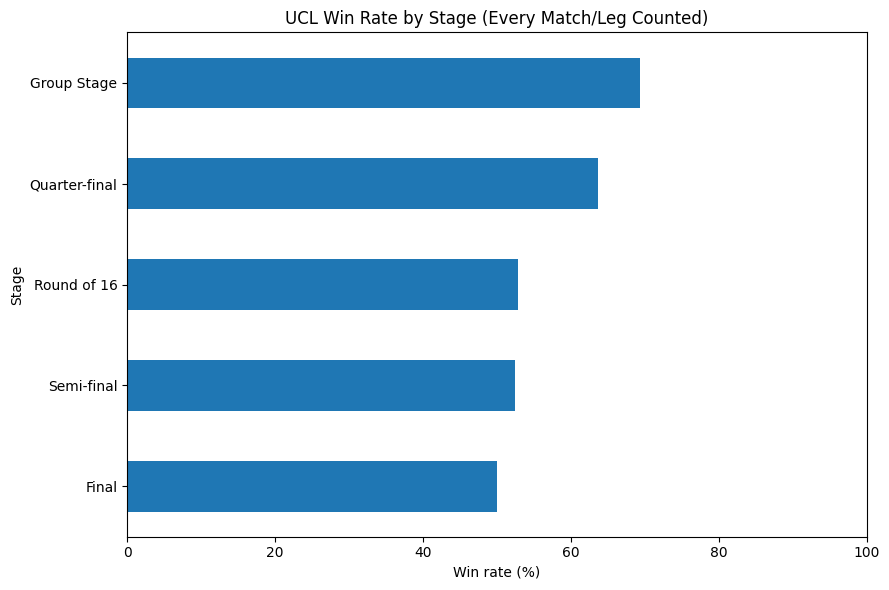

In [29]:
d = ucl[ucl.result.isin(["W","D","L"])]
counts_legs = d.groupby(["stage","result"]).size().unstack(fill_value=0).reindex(columns=["W","D","L"], fill_value=0)
counts_legs["matches"] = counts_legs[["W","D","L"]].sum(axis=1)
counts_legs["win_rate_pct"] = 100 * counts_legs["W"] / counts_legs["matches"]
counts_legs = counts_legs.sort_values("win_rate_pct", ascending=False)
display(counts_legs)
v = counts_legs.win_rate_pct.sort_values()
v.plot(kind="barh", figsize=(9,6), title="UCL Win Rate by Stage (Every Match/Leg Counted)")
plt.xlabel("Win rate (%)"); plt.ylabel("Stage"); plt.xlim(0,100)
savefig("ronaldo-ucl-win-rate-by-stage-legs.png")